# 06 - Evaluate Baseline

Name: Usha Oudeacoumar
Student ID: 20057009
Email: 20057009@mydbs.ie

This notebook checks how good the two baseline models are before we go anywhere near
the future years data. It uses the validation set we held back in notebook 05 (still
from the development years 2011-2014, just not used for training). For each model it
works out AUROC (how well it ranks admitted vs not admitted), Brier score, calibration
intercept and slope, and expected calibration error (ECE), plus draws a calibration
plot. If a model looks bad here there is no point testing it on later years.

In [1]:
import sys
sys.path.append(".")
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from utils import PROC_DIR, MODELS_DIR, OUT_TABLES, OUT_FIGS, get_all_metrics

os.makedirs(OUT_TABLES, exist_ok=True)
os.makedirs(OUT_FIGS, exist_ok=True)

log_reg = joblib.load(os.path.join(MODELS_DIR, "log_reg_model.pkl"))
gb = joblib.load(os.path.join(MODELS_DIR, "gb_model.pkl"))
feat_cols = joblib.load(os.path.join(MODELS_DIR, "feat_cols.pkl"))

val_df = pd.read_csv(os.path.join(PROC_DIR, "dev_val.csv"))
X_val, y_val = val_df[feat_cols], val_df["admit"]
val_df.shape

Matplotlib is building the font cache; this may take a moment.


(17075, 92)

In [3]:
# get predicted probabilities from both models on the validation set
p_log_reg = log_reg.predict_proba(X_val)[:, 1]
p_gb = gb.predict_proba(X_val)[:, 1]

metrics_log_reg = get_all_metrics(y_val, p_log_reg)
metrics_gb = get_all_metrics(y_val, p_gb)

metrics_table = pd.DataFrame([
    {"model": "logistic_regression", **metrics_log_reg},
    {"model": "gradient_boosting", **metrics_gb},
])
metrics_table

/Users/vivek_gobi@optum.com/Library/CloudStorage/OneDrive-UHG/Desktop/new_desktop/Personal/usha college projects/ClinicalTemporalRecalibration/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/vivek_gobi@optum.com/Library/CloudStorage/OneDrive-UHG/Desktop/new_desktop/Personal/usha college projects/ClinicalTemporalRecalibration/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' ins

,model,auroc,brier,cal_intercept,cal_slope,ece
0,logistic_regression,0.820875,0.092033,0.017647,1.006712,0.009267
1,gradient_boosting,0.829765,0.090150,0.105577,1.066421,0.009966


In [4]:
metrics_table.to_csv(os.path.join(OUT_TABLES, "06_internal_validation_metrics.csv"), index=False)

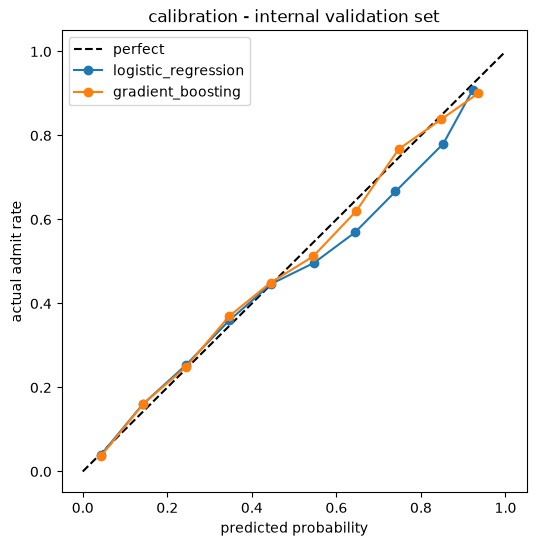

In [5]:
# calibration plot, bin predictions and compare to the actual admit rate in each bin
def calibration_points(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mean_pred = []
    mean_true = []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (y_prob > lo) & (y_prob <= hi) if i > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() == 0:
            continue
        mean_pred.append(y_prob[mask].mean())
        mean_true.append(np.asarray(y_true)[mask].mean())
    return mean_pred, mean_true

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="perfect")

pred1, true1 = calibration_points(y_val, p_log_reg)
plt.plot(pred1, true1, marker="o", label="logistic_regression")

pred2, true2 = calibration_points(y_val, p_gb)
plt.plot(pred2, true2, marker="o", label="gradient_boosting")

plt.xlabel("predicted probability")
plt.ylabel("actual admit rate")
plt.title("calibration - internal validation set")
plt.legend()
plt.savefig(os.path.join(OUT_FIGS, "06_calibration_internal_validation.png"))
plt.show()